# 10 · 로봇은 세상을 어떻게 보나 — 깊이 영상에서 거리 지도까지

> 깊이 카메라 영상을 3D 점으로, 3D 점을 격자 지도로, 격자 지도를 거리장으로 바꿔야 충돌 비용을 계산할 수 있다. 지도가 "모르는" 곳은 "비어 있는" 곳이 아니다.

**지금 위치**

01~04 기초·MPC → 05~07 MPPI → 08~09 로봇팔 → **10 지도** → 11 손 비용 → 12 결과 → 13 Isaac Sim

**이 노트를 끝내면**
1. 깊이 영상의 픽셀 하나를 로봇 좌표의 3D 점으로 바꿀 수 있다.
2. 격자 지도의 세 상태(점유·빈 칸·모름)가 어떻게 정해지는지 설명할 수 있다.
3. 거리장이 왜 필요한지, 그리고 "모름" 영역 때문에 충돌 비용이 0이 될 수 있는 이유를 설명할 수 있다.

**필요한 것:** [06](06_mppi_obstacles.ipynb)·[08](08_robot_arm.ipynb)의 η 비용(간격 → 비용), [09](09_curobo_franka.ipynb)의 충돌 구 · **예상 시간:** 40분

## 복습 퀴즈 (08~09)

<details><summary>1. 충돌 구의 "간격(gap)"은 어떻게 계산하나?</summary>

장애물까지의 거리에서 구 반지름을 뺀다. 양수면 떨어져 있고, 음수면 겹친다.
</details>

<details><summary>2. 간격이 η보다 크면 η 비용은 얼마인가?</summary>

0이다. η는 비용이 켜지기 시작하는 거리다. η 안으로 들어오면 2차 함수로 커지고, 겹치면 직선으로 커진다.
</details>

<details><summary>3. 실험에서 충돌 구에 buffer 20 mm를 더했다. 로그의 간격과 "buffer 제외" 간격은 얼마나 차이 나나?</summary>

정확히 20 mm. 로그 간격은 buffer를 포함한 큰 구 기준이라 20 mm 작게(더 가깝게) 나온다.
</details>

In [1]:
import csv
import numpy as np
from scipy.ndimage import distance_transform_edt
from common import *
import realdata as rd
import grid2d as g2
plt = setup_plot()

## 1. 깊이 카메라 — 장애물이 어디 있는지 어떻게 아나

### 문제
06~09 노트에서는 장애물 위치를 처음부터 알고 있었다. `obstacles = [((0.5, 0.0), 0.15)]`처럼 코드에 직접 적어 넣었다. 실제 로봇은 장애물 목록을 받지 못한다. 손이 어디 있는지 **눈으로 봐야** 한다.

### 아이디어
이 프로젝트는 **깊이 카메라**(depth camera, Intel RealSense D435i)를 쓴다. 보통 카메라는 픽셀마다 색을 주지만, 깊이 카메라는 픽셀마다 **카메라에서 그 점까지의 거리**(정확히는 카메라가 보는 방향으로의 거리 $z$)를 준다. 그 결과가 깊이 영상(depth image)이다.

거리를 재지 못한 픽셀은 값이 0이다. 빛이 반사되어 돌아오지 않았거나, 너무 가깝거나 멀었던 경우다.

아래는 실험에서 기록한 실제 프레임 하나다. 카메라 앞에 손바닥을 세워 둔 장면이다.

영상 크기 (480, 640) (세로, 가로 픽셀) | 값의 단위: m
거리를 잰 픽셀 20.8%, 못 잰 픽셀(값 0) 79.2%
가운데 근처 픽셀 (행 240, 열 330)의 깊이: 0.406 m


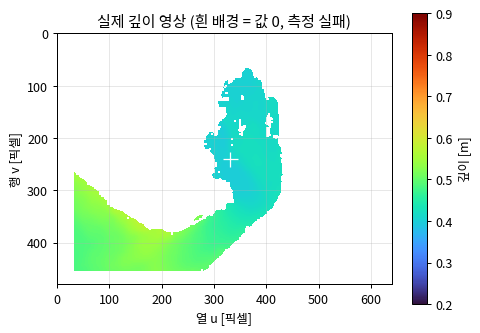

In [2]:
rec = rd.FRAMES[81]
d = rd.load_depth(rec, mask_edges=False)
print('영상 크기', d.shape, '(세로, 가로 픽셀) | 값의 단위: m')
print('거리를 잰 픽셀 %.1f%%, 못 잰 픽셀(값 0) %.1f%%' % (100 * (d > 0).mean(), 100 * (d == 0).mean()))
v, u = 240, 330
print(f'가운데 근처 픽셀 (행 {v}, 열 {u})의 깊이: {d[v, u]:.3f} m')

plt.figure(figsize=(6, 4.2))
plt.imshow(np.where(d > 0, d, np.nan), cmap='turbo', vmin=0.2, vmax=0.9)
plt.colorbar(label='깊이 [m]')
plt.plot(u, v, 'w+', ms=12)
plt.title('실제 깊이 영상 (흰 배경 = 값 0, 측정 실패)')
plt.xlabel('열 u [픽셀]'); plt.ylabel('행 v [픽셀]')
plt.show()

**결과 해석:** 가운데 위쪽의 하늘색 덩어리(약 0.4 m)가 손바닥이고, 왼쪽 아래로 이어진 연두색(약 0.5 m)이 손목과 팔뚝이다. 나머지 흰 부분은 값이 0이다. 기록할 때 0.7 m보다 먼 깊이는 잘라 냈고(`clipping_distance_m: 0.7`), 빛이 돌아오지 않은 곳도 0이 된다. 이 "값 0" 픽셀이 5절의 핵심 문제와 이어진다.

## 2. 픽셀을 3D 점으로 — 역투영

### 문제
깊이 영상은 "몇 번째 행, 몇 번째 열 픽셀이 몇 m"라는 정보다. 그런데 충돌을 계산하려면 "로봇 기준으로 x, y, z가 몇 m인 점"이 필요하다.

### 아이디어
카메라를 바늘구멍 하나로 생각한다(핀홀 카메라). 영상 가운데 픽셀은 카메라 정면 방향이다. 가운데에서 옆으로 멀어진 픽셀일수록 옆 방향으로 비스듬한 광선이다. 닮은 삼각형으로 생각하면, 깊이 $z$인 점이 영상 가운데에서 $(u - c_x)$ 픽셀 떨어져 찍혔을 때 실제 옆 거리는 $(u - c_x)\cdot z / f_x$다.

$$
x_{cam} = \frac{(u - c_x)\,z}{f_x},\qquad y_{cam} = \frac{(v - c_y)\,z}{f_y},\qquad z_{cam} = z
$$

- $(c_x, c_y)$: 영상의 중심 픽셀
- $f_x, f_y$: 초점 거리(픽셀 단위). 값이 클수록 같은 옆 거리가 영상에서 더 크게 찍힌다.

이 네 숫자를 카메라 **내부 파라미터**(intrinsics)라고 한다. 이렇게 픽셀과 깊이에서 3D 점을 되찾는 계산을 **역투영**(back-projection)이라고 한다.

그다음 카메라 좌표를 로봇 좌표로 옮긴다. 카메라가 로봇 기준으로 어디에(평행이동 $t$), 어느 방향으로(회전 $R$) 놓였는지 알면 $p_{robot} = R\,p_{cam} + t$다.

**예측해 보기:** 위의 가운데 근처 픽셀(행 240, 열 330)은 영상 중심과 거의 같은 위치다. 이 점의 카메라 좌표 $x_{cam}, y_{cam}$은 0에 가까울까?

In [3]:
fx, fy, cx, cy = rd.K[0, 0], rd.K[1, 1], rd.K[0, 2], rd.K[1, 2]
print(f'내부 파라미터 fx={fx:.1f}, fy={fy:.1f}, cx={cx:.1f}, cy={cy:.1f}')

z = d[v, u]
p_cam = np.array([(u - cx) * z / fx, (v - cy) * z / fy, z])
p_robot = rd.R_CAM @ p_cam + rd.T_CAM
print('카메라 좌표 [m]:', p_cam.round(4))
print('로봇 좌표   [m]:', p_robot.round(4))
print('카메라 정면(z축)이 로봇 좌표에서 가리키는 방향:', (rd.R_CAM @ [0, 0, 1]).round(3))

내부 파라미터 fx=606.2, fy=606.4, cx=324.0, cy=237.4
카메라 좌표 [m]: [0.004  0.0017 0.406 ]
로봇 좌표   [m]: [0.553  0.0181 0.3814]
카메라 정면(z축)이 로봇 좌표에서 가리키는 방향: [1. 0. 0.]


**결과 해석:** 중심에 가까운 픽셀이라 $x_{cam}, y_{cam}$은 수 mm 이내로 작다. 카메라 정면이 로봇의 $+x$ 방향이므로, 로봇 좌표로는 x가 깊이만큼 앞으로 나간 점이 된다. 카메라는 로봇 쪽에서 손 쪽(+x)을 바라보고 있다.

같은 계산을 모든 픽셀에 한 번에 적용한다. 이렇게 얻은 3D 점 묶음을 **점구름**(point cloud)이라고 한다.

점구름: (63975, 3) (점 개수, xyz)


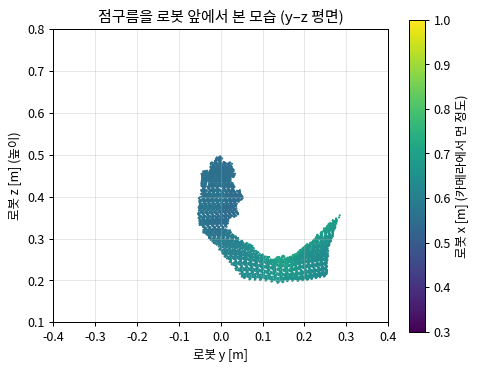

In [4]:
pc, ys, xs = rd.backproject(rd.load_depth(rec))   # 실험 코드처럼 영상 가장자리 띠를 0으로 지운 뒤 역투영
print('점구름:', pc.shape, '(점 개수, xyz)')

sub = pc[::15]
fig, ax = plt.subplots(figsize=(6, 4.5))
sc = ax.scatter(sub[:, 1], sub[:, 2], s=0.5, c=sub[:, 0], cmap='viridis', vmin=0.3, vmax=1.0)
plt.colorbar(sc, label='로봇 x [m] (카메라에서 먼 정도)')
ax.set_xlabel('로봇 y [m]'); ax.set_ylabel('로봇 z [m] (높이)'); ax.set_aspect('equal')
ax.set_xlim(-0.4, 0.4); ax.set_ylim(0.1, 0.8)
ax.set_title('점구름을 로봇 앞에서 본 모습 (y–z 평면)')
plt.show()

**결과 해석:** 위쪽의 세로로 긴 덩어리가 손바닥(높이 z 약 0.30~0.50 m)이고, 오른쪽 아래로 휘어진 부분이 손목과 팔뚝이다. 색이 진할수록 x가 작아 로봇에 가깝다. 손바닥이 팔뚝보다 로봇 쪽으로 나와 있다. 이제 장애물을 로봇 좌표로 표현할 수 있게 되었다.

**한 문장으로:** 역투영에 필요한 정보 세 가지(픽셀 위치, 깊이, 카메라 파라미터)를 넣어 설명해 보자.

`backproject`는 `realdata.py`에 저장해 두었고, 11 노트에서 다시 쓴다.

## 3. 점구름에서 격자 지도로

### 문제
점구름을 그대로 장애물로 쓰면 곤란한 점이 있다.
- 한 프레임에 점이 수만 개다(위 프레임은 약 6만 개). 1초에 30프레임씩 쌓으면 점이 끝없이 늘어난다.
- 같은 표면을 여러 번 보면 노이즈 때문에 점이 조금씩 다른 위치에 찍힌다.
- 가장 중요한 문제: 점구름은 "여기 무언가 있다"만 말해 준다. **"여기는 비어 있다"** 와 **"여기는 아직 못 봤다"** 를 구분하지 못한다.

### 아이디어
공간을 일정한 크기의 칸으로 나누고, 칸마다 상태를 기록한다. 3D에서 이 칸을 **voxel**(부피 픽셀)이라고 부른다. 칸 크기는 설정값이다(이 실험은 3 cm).

칸의 상태는 광선을 따라가며 정한다. 카메라에서 나간 광선이 표면에서 멈췄다면,
- 광선이 **지나간** 칸들: 빛이 통과했으니 **비어 있다**(free).
- 광선이 **멈춘** 칸: 무언가 있다, **점유**(occupied).
- 광선이 한 번도 닿지 않은 칸: **모른다**(unknown).

이렇게 칸마다 점유/빈 칸/모름을 기록한 지도를 **occupancy 지도**라고 한다.

3D로 하면 그림이 복잡하므로, 같은 원리를 **2D 격자**로 확인한다. 1 cm 칸, 카메라는 왼쪽에서 오른쪽(+x)을 본다. 손바닥(얇은 막대)과 뒤쪽 벽이 있고, 실제 카메라처럼 **손끝 위쪽 일부 광선은 깊이가 돌아오지 않게** 만들었다.

광선 160 개 중 깊이가 돌아온 광선 86 개


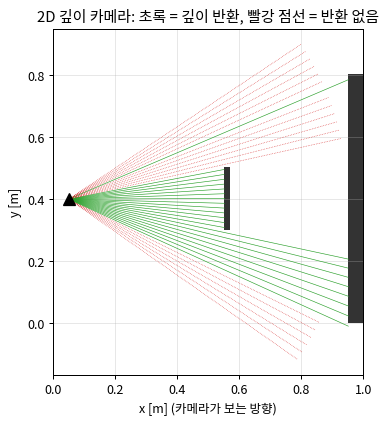

In [5]:
truth = g2.make_world([g2.PALM, g2.WALL])
depths = g2.raycast(truth)
print('광선', g2.NRAY, '개 중 깊이가 돌아온 광선', np.isfinite(depths).sum(), '개')

fig, ax = plt.subplots(figsize=(7, 5))
g2.show_rays(ax, truth, depths)
ax.set_title('2D 깊이 카메라: 초록 = 깊이 반환, 빨강 점선 = 반환 없음')
plt.show()

### 지도 갱신 코드
칸마다 **점수**를 둔다. 빈 칸이라는 증거가 나오면 점수를 내리고(−0.4), 점유라는 증거가 나오면 올린다(+0.85). 여러 프레임에서 같은 결과가 반복되면 점수가 한쪽으로 쌓여 확신이 커진다. 한 번도 갱신되지 않은 칸은 "모름"으로 둔다.

(이 점수는 확률을 다루기 편하게 바꾼 값으로 **log-odds**라고 부른다. 0보다 크면 점유 쪽, 작으면 빈 칸 쪽이다.)

**깊이가 돌아오지 않은 광선은 아무 칸도 갱신하지 않는다.** 표면이 어디인지 모르니 "어디까지 비었다"고도 말할 수 없기 때문이다.

In [6]:
S_FREE, S_OCC, S_MIN, S_MAX = -0.4, 0.85, -2.0, 3.5

def integrate(score, seen, depths):
    for a, dep in zip(g2.ANGLES, depths):
        if not np.isfinite(dep):
            continue                                        # 깊이 없음: 갱신하지 않음
        dvec = g2.ray_dir(a)
        hit = g2.cell(g2.CAM + dep * dvec)
        passed = {g2.cell(g2.CAM + r * dvec) for r in np.arange(0.02, dep - g2.RES, g2.RES / 4)} - {hit}
        for c in passed:
            score[c] += S_FREE; seen[c] = True              # 광선이 지나간 칸: 빈 칸 쪽으로
        score[hit] += S_OCC; seen[hit] = True               # 광선이 멈춘 칸: 점유 쪽으로
    np.clip(score, S_MIN, S_MAX, out=score)

def classify(score, seen):
    state = np.full(score.shape, g2.UNKNOWN)
    state[seen & (score < 0)] = g2.FREE
    state[seen & (score > 0)] = g2.OCC
    return state

score = np.zeros((g2.NX, g2.NY)); seen = np.zeros((g2.NX, g2.NY), bool)
for _ in range(5):                                          # 같은 장면을 5프레임
    integrate(score, seen, g2.raycast(truth))
state = classify(score, seen)
print('빈 칸 / 점유 / 모름 칸 수:', [(state == k).sum() for k in (g2.FREE, g2.OCC, g2.UNKNOWN)])

빈 칸 / 점유 / 모름 칸 수: [1808, 46, 6146]


**예측해 보기:** 그림에서 회색("모름")은 어디에 생길까? 세 군데를 떠올려 보자.

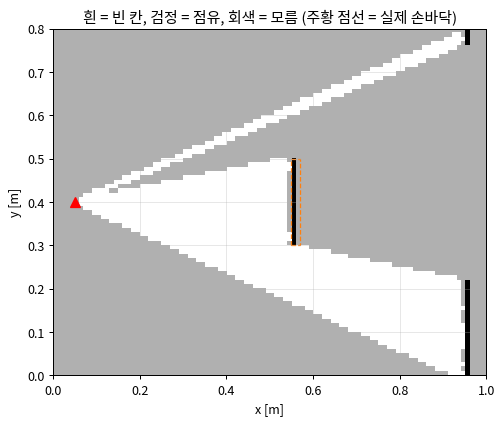

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
g2.show_state(ax, state, '흰 = 빈 칸, 검정 = 점유, 회색 = 모름 (주황 점선 = 실제 손바닥)')
plt.show()

**결과 해석:** 회색은 세 종류다.
1. **시야 밖**: 카메라 시야각 바깥(위·아래).
2. **손바닥 뒤 가림 영역**: 광선이 손바닥에서 멈추니 그 뒤는 볼 수 없다.
3. **깊이 미반환 쐐기**: 손바닥 위쪽으로 뻗은 회색 띠. 광선은 나갔지만 깊이가 돌아오지 않아 갱신되지 않았다.

셋 다 "모른다"이지 "비어 있다"가 아니다. 특히 2와 3이 실제 실험에서 문제를 일으켰다(5~6절).

**한 문장으로:** 광선이 "지나간 칸"과 "닿지 않은 칸"이 왜 다른 상태가 되는지 설명해 보자.

## 4. 거리장 — "장애물까지 얼마나 먼가"를 빨리 답하기

### 문제
η 비용은 **간격**, 즉 장애물까지의 거리가 있어야 계산된다(08 노트). occupancy 지도는 칸마다 "점유인가?"만 알려 준다. 거리를 알려면 가장 가까운 점유 칸을 찾아야 한다.

매번 모든 점유 칸까지 거리를 재면 느리다. 실험에서는 매 제어 주기마다 후보 400개 × 시점 30개 × 충돌 구 61개 = 약 73만 번 거리를 물어야 한다.

### 아이디어
지도가 바뀔 때 **모든 칸에 대해 "가장 가까운 장애물까지의 거리"를 미리 계산해서 표로 저장**해 둔다. 그러면 거리 질문은 표에서 값 하나를 읽는 일로 끝난다.

이 표를 **거리장**(distance field)이라고 한다. 유클리드 거리를 쓰고 장애물 안쪽은 음수로 표시하는 것을 **ESDF**(Euclidean Signed Distance Field)라고 부른다.

충돌 구 하나에 대해서는 **구 중심 위치의 거리값**을 읽고 반지름을 뺀다.

$$
\text{간격} = d(\text{구 중심}) - r
$$

거리장은 직접 짜도 되지만, scipy의 `distance_transform_edt`가 "각 칸에서 가장 가까운 0 칸까지 거리"를 계산해 준다.

점 [0.45 0.4 ]에서 읽은 거리: 0.100 m (손바닥 앞면 x=0.55까지 약 0.10 m)


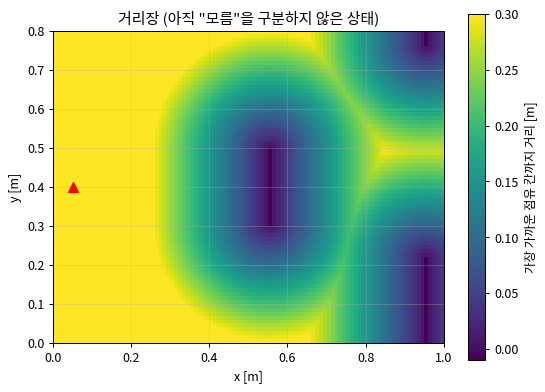

In [8]:
occ = state == g2.OCC
esdf = (distance_transform_edt(~occ) - distance_transform_edt(occ)) * g2.RES   # [m], 바깥 +, 안쪽 -

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(esdf.T, origin='lower', extent=[0, 1, 0, 0.8], cmap='viridis', vmax=0.3)
plt.colorbar(im, label='가장 가까운 점유 칸까지 거리 [m]')
ax.plot(*g2.CAM, 'r^', ms=8); ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]')
ax.set_title('거리장 (아직 "모름"을 구분하지 않은 상태)')
plt.show()

c = np.array([0.45, 0.40])
print(f'점 {c}에서 읽은 거리: {esdf[g2.cell(c)]:.3f} m (손바닥 앞면 x=0.55까지 약 0.10 m)')

**결과 해석:** 장애물(손바닥, 벽)에서 멀어질수록 밝아진다. 점 (0.45, 0.40)에서 표를 한 번 읽으니 손바닥까지 약 0.10 m가 나왔다.

그런데 이 그림에는 문제가 있다. 회색("모름") 칸도 거리값을 가지고 있다. 손바닥 뒤처럼 실제로는 무엇이 있는지 모르는 곳이 "장애물에서 몇 cm 떨어진 안전한 곳"처럼 보인다.

## 5. 모르는 곳은 비어 있는 곳이 아니다

### 문제
"모름" 칸에서 거리를 물으면 무엇을 돌려줘야 할까? 실제 시스템(nvblox)은 이런 칸에 대해 정상적인 거리 대신 **특수값 −100**을 돌려준다. 이렇게 "정상 값이 아님"을 알리는 약속된 값을 **sentinel**이라고 한다. −100 m라는 거리가 있다는 뜻이 아니다.

그리고 실험에서는 **이 sentinel이 나온 충돌 구의 비용이 0**이었다. 지도가 모르는 곳에 있는 구는 비용을 받지 않은 것이다.

### 아이디어
같은 상황을 토이로 만든다. 반지름 7 cm 구 두 개를 놓는다(실험의 Franka 구 하나: 원래 5 cm + buffer 2 cm).
- **구 A**: 중심이 손끝 위 "깊이 미반환 쐐기" 안. 구 표면은 손바닥 위쪽 끝과 겹친다.
- **구 B**: 중심이 손바닥 뒤 "가림 영역" 안. 구 표면은 손바닥 앞면과 겹친다.

두 가지 방법으로 비용을 계산한다.
1. **지도 방식:** 구 중심의 거리장 값을 읽는다. 중심이 "모름"이면 −100 → 비용 0.
2. **관측점 방식:** 카메라가 실제로 본 손 표면 점들까지 거리를 직접 잰다.

**예측해 보기:** 두 구 모두 손바닥과 겹친다. 지도 방식의 비용은 얼마가 나올까? 관측점 방식은?

In [9]:
SENTINEL = -100.0
esdf_raw = np.where(state == g2.UNKNOWN, SENTINEL, esdf)    # 모름 칸은 sentinel

W, ETA = 1e5, 0.025                                         # 실험의 환경 충돌 비용 weight, η
spheres = {'A (손끝 위 미반환)': (np.array([0.50, 0.53]), 0.07),
           'B (손바닥 뒤 가림)': (np.array([0.60, 0.42]), 0.07)}

# 관측점: 깊이가 돌아온 광선의 끝점 중 손 주변 상자 안
pts = np.array([g2.CAM + dep * g2.ray_dir(a) for a, dep in zip(g2.ANGLES, depths) if np.isfinite(dep)])
hand_pts = pts[(pts[:, 0] > 0.45) & (pts[:, 0] < 0.65) & (pts[:, 1] > 0.28) & (pts[:, 1] < 0.56)]

for name, (c, r) in spheres.items():
    raw = esdf_raw[g2.cell(c)]
    st = ['빈 칸', '점유', '모름'][state[g2.cell(c)]]
    map_cost = 0.0 if raw <= -99 else float(eta_cost(raw - r, ETA, W))   # sentinel이면 비용 0
    gap_pts = np.linalg.norm(hand_pts - c, axis=1).min() - r
    pts_cost = float(eta_cost(gap_pts, ETA, W))
    print(f'{name}: 중심 상태={st}, 중심 거리값={raw:.1f} → 지도 방식 비용 {map_cost:.0f} | '
          f'관측점까지 간격 {1000*gap_pts:.1f} mm → 관측점 방식 비용 {pts_cost:.0f}')

A (손끝 위 미반환): 중심 상태=모름, 중심 거리값=-100.0 → 지도 방식 비용 0 | 관측점까지 간격 -11.1 mm → 관측점 방식 비용 2362
B (손바닥 뒤 가림): 중심 상태=모름, 중심 거리값=-100.0 → 지도 방식 비용 0 | 관측점까지 간격 -22.1 mm → 관측점 방식 비용 3463


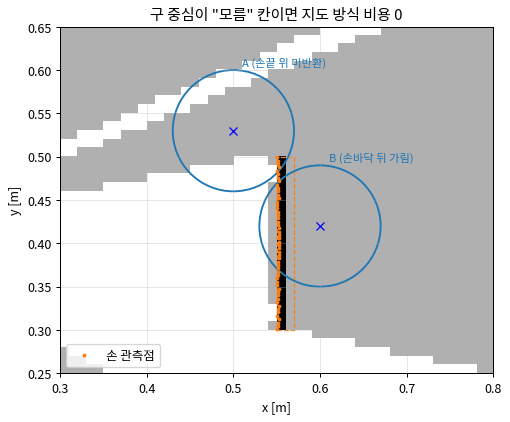

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
g2.show_state(ax, state, '구 중심이 "모름" 칸이면 지도 방식 비용 0')
ax.plot(hand_pts[:, 0], hand_pts[:, 1], '.', color='tab:orange', ms=4, label='손 관측점')
for name, (c, r) in spheres.items():
    ax.add_patch(plt.Circle(c, r, fill=False, ec='tab:blue', lw=1.5))
    ax.plot(*c, 'bx'); ax.text(c[0] + 0.01, c[1] + 0.075, name, color='tab:blue', fontsize=9)
ax.set_xlim(0.3, 0.8); ax.set_ylim(0.25, 0.65); ax.legend(loc='lower left')
plt.show()

**결과 해석:** 두 구 모두 손 표면과 겹치는데(관측점 간격이 음수), 지도 방식의 비용은 0이다. 구 **외곽**이 손과 겹쳐도, 비용은 구 **중심 한 점**의 거리값으로 계산되기 때문이다. 중심이 "모름" 칸이면 비용이 사라진다.

반대로 관측점까지 거리를 직접 재면 구 중심이 어디에 있든 겹침이 드러나고 비용이 커진다. 이것이 11 노트에서 손 관측점을 **따로 장애물로 넣는** 이유다.

**직접 해보기:** 구 A의 중심을 `[0.50, 0.45]`(손바닥 앞, 관측된 빈 칸)로 옮기고 다시 실행해 보자.
<details><summary>예상 결과</summary>

중심이 관측된 빈 칸이 되어 정상 거리값을 읽는다. 지도 방식으로도 간격이 음수 또는 η 이내가 되어 큰 비용이 나온다. 같은 겹침이라도 구 중심이 어느 칸에 있느냐에 따라 결과가 달라진다는 점이 문제의 핵심이다.
</details>

**한 문장으로:** "모르는 곳은 비어 있는 곳이 아니다"가 충돌 비용에서 왜 중요한지 설명해 보자.

## 6. 실제 실험에서 일어난 일

토이에서 본 일이 실제 Baseline 실험(조건 R, 손 전용 비용 없음)에서 그대로 일어났다. 레포의 진단 파일 `docs/data/R-nvblox-nearest.csv`에 step 150~175의 기록이 있다.

| 열 | 뜻 |
|---|---|
| `clearance_mm` | 손 관측면과 가장 가까운 충돌 구 사이 간격 (buffer 20 mm 포함) |
| `center_raw_sdf_m` | 그 구 중심에서 읽은 거리장 원래 값 |
| `all_spheres_nvblox_cost` | 로봇 전체 구의 지도(nvblox) 충돌 비용 합 |
| `roi_low_cost` | 같은 자세를 손 관측점 방식(η = 25 mm)으로 계산한 비용 |

구 중심 거리값의 종류: [-100.0]
겹친 step: [158, 159, 160, 161, 162, 163, 164]
겹친 동안 지도 비용 합: 0.0 | 같은 자세의 관측점 방식 비용 최대: 104123.5
step 163: {'link': 'panda_link5', 'sphere_index': '30', 'clearance_mm': '-29.54002097249031', 'center_raw_sdf_m': '-100.0', 'all_spheres_nvblox_cost': '0.0', 'roi_low_cost': '18502.576171875'}


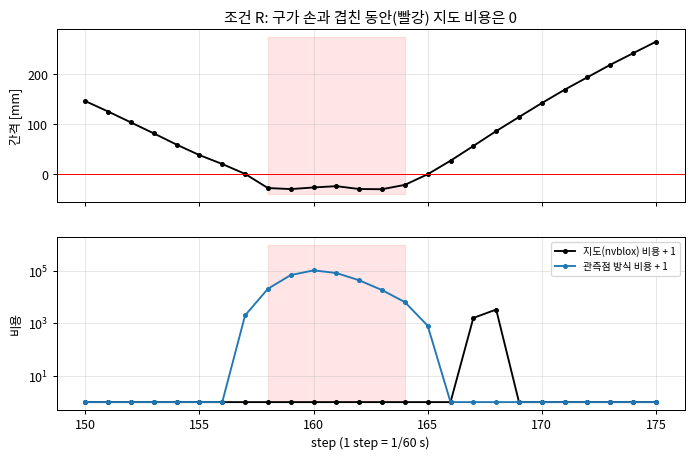

In [11]:
rows = list(csv.DictReader(open(REPO / 'docs/data/R-nvblox-nearest.csv', encoding='utf-8')))
col = lambda k: np.array([float(r[k]) for r in rows])
step, clear, nv_cost, roi_cost = col('step'), col('clearance_mm'), col('all_spheres_nvblox_cost'), col('roi_low_cost')
overlap = clear < 0
print('구 중심 거리값의 종류:', sorted(set(col('center_raw_sdf_m'))))
print('겹친 step:', step[overlap].astype(int).tolist())
print('겹친 동안 지도 비용 합: %.1f | 같은 자세의 관측점 방식 비용 최대: %.1f' % (nv_cost[overlap].sum(), roi_cost[overlap].max()))
r163 = next(r for r in rows if int(float(r['step'])) == 163)
print('step 163:', {k: r163[k] for k in ['link', 'sphere_index', 'clearance_mm', 'center_raw_sdf_m', 'all_spheres_nvblox_cost', 'roi_low_cost']})

fig, axs = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
axs[0].plot(step, clear, 'k.-'); axs[0].axhline(0, color='r', lw=0.8)
axs[0].fill_between(step, clear.min() - 10, clear.max() + 10, where=overlap, color='r', alpha=0.1)
axs[0].set_ylabel('간격 [mm]'); axs[0].set_title('조건 R: 구가 손과 겹친 동안(빨강) 지도 비용은 0')
axs[1].semilogy(step, nv_cost + 1, 'k.-', label='지도(nvblox) 비용 + 1')
axs[1].semilogy(step, roi_cost + 1, '.-', color=COLORS['LOW'], label='관측점 방식 비용 + 1')
axs[1].fill_between(step, 1, 1e6, where=overlap, color='r', alpha=0.1)
axs[1].set_xlabel('step (1 step = 1/60 s)'); axs[1].set_ylabel('비용'); axs[1].legend(fontsize=8)
plt.show()

**결과 해석:**
- step 158~164의 7스텝 동안 로봇 구가 손 관측면과 겹쳤다(간격 음수). 그동안 지도 비용 합은 **0**이다.
- step 163이 가장 깊이 겹친 순간이다. `panda_link5`의 구 30번이 buffer 포함 −29.5 mm 겹쳤고, 그 구 중심의 거리값은 **−100(sentinel)** 이었다.
- 같은 자세를 관측점 방식으로 계산하면 비용이 1만~10만 단위다(step 163에서 18,502.6).
- 그래프 뒤쪽(step 167~168)에서는 지도 비용이 양수다. 지도 비용이 통째로 꺼진 것이 아니라 **손과 겹친 위치에서만 비어 있었다**는 뜻이다.

레포의 원인 분석(`docs/diagnosis.md`)에 따르면 구 30번의 중심은 손끝 위 깊이 미반환 영역에, 일부 그리퍼 구 중심은 손바닥 뒤 가림 영역에 있었다. 5절 토이의 구 A, B와 같은 상황이다.

## 7. 움직이는 물체의 잔상과 decay

### 문제
손이 다른 곳으로 옮겨 가면 지도는 어떻게 될까? 옛 위치가 계속 보인다면 광선이 그 칸을 지나가며 "빈 칸" 점수를 쌓으니 점유 표시가 지워진다. 그런데 **옛 위치가 가려지면** 그 칸을 갱신할 광선이 없다. 점유 표시가 영원히 남는다. 이런 가짜 장애물을 **잔상**(ghost obstacle)이라고 한다.

### 아이디어
매 프레임 지도를 갱신하기 전에 모든 칸의 점수를 조금씩 0 쪽으로 줄인다(여기서는 0.85배). 계속 보이는 물체는 매번 다시 점수를 받아 유지되고, 더는 보이지 않는 칸은 점점 확신을 잃는다. 이를 **decay**(감쇠)라고 한다.

아래에서 물체가 A 위치에 10프레임 있다가, 카메라 쪽으로 옮겨 와서 A를 가리는 경우를 본다.

마지막 프레임 점수: decay 없음 3.50, decay 있음 0.005


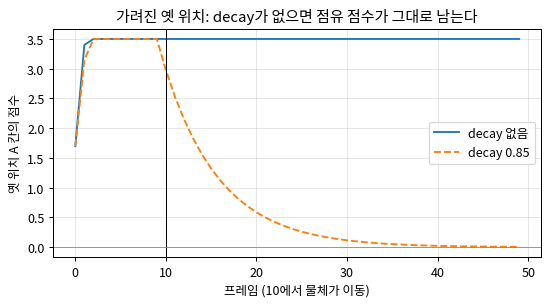

In [12]:
A_BOX = (0.60, 0.64, 0.36, 0.44)
before = g2.make_world([A_BOX, g2.WALL])
after = g2.make_world([(0.35, 0.38, 0.33, 0.47), g2.WALL])     # 앞으로 옮겨 와 A를 가림
probe = g2.cell(np.array([0.605, 0.40]))                         # A 앞면 칸

hist = {}
for use_decay in (False, True):
    sc_, sn_ = np.zeros((g2.NX, g2.NY)), np.zeros((g2.NX, g2.NY), bool)
    h = []
    for k in range(50):
        if use_decay:
            sc_ *= 0.85                                          # decay: 갱신 전에 점수를 0 쪽으로
        integrate(sc_, sn_, g2.raycast(before if k < 10 else after, dropout=None))
        h.append(sc_[probe])
    hist[use_decay] = np.array(h)

plt.figure(figsize=(7, 3.3))
plt.plot(hist[False], label='decay 없음')
plt.plot(hist[True], '--', label='decay 0.85')
plt.axvline(10, color='k', lw=0.8); plt.axhline(0, color='gray', lw=0.6)
plt.xlabel('프레임 (10에서 물체가 이동)'); plt.ylabel('옛 위치 A 칸의 점수'); plt.legend()
plt.title('가려진 옛 위치: decay가 없으면 점유 점수가 그대로 남는다')
plt.show()
print('마지막 프레임 점수: decay 없음 %.2f, decay 있음 %.3f' % (hist[False][-1], hist[True][-1]))

**결과 해석:** decay가 없으면 옛 위치 점수가 양수 그대로 남아 계속 장애물로 보인다(잔상). decay가 있으면 점수가 0 근처로 줄어든다. 단, **0으로 돌아간다는 것은 "모름"이 된다는 뜻이지 "빈 칸"이 된다는 뜻이 아니다.** 빈 칸이라는 증거는 새 광선이 그 칸을 지나가야만 생긴다.

이번 최종 실험은 손을 고정한 정적 장면이라 잔상 문제의 영향이 작았다. 실험 코드는 매 깊이 프레임마다 decay를 먼저 하고 새 프레임을 적분한다(아래 "실제 프로젝트에서는" 참고).

> **참고 (TSDF):** 지도를 만드는 다른 방식으로, 칸마다 "가장 가까운 표면까지 거리"를 표면 근처에서만 기록하고 여러 프레임을 평균하는 TSDF가 있다. 표면을 정밀하게 재구성할 때 쓴다. 이 실험의 nvblox 설정은 occupancy 방식이다.

## 핵심 정리

- **깊이 카메라**는 픽셀마다 거리를 준다. 값 0은 측정 실패다.
- **역투영**: 픽셀 위치·깊이·내부 파라미터로 카메라 좌표 3D 점을 얻고, 카메라 pose $(R, t)$로 로봇 좌표로 옮긴다. 결과가 점구름이다.
- **occupancy 지도**: 광선이 지나간 칸은 빈 칸, 멈춘 칸은 점유, 닿지 않은 칸은 모름. 깊이가 없는 광선은 아무것도 갱신하지 않는다.
- **거리장(ESDF)**: 칸마다 가장 가까운 장애물까지 거리를 미리 계산한 표. 충돌 구는 **중심** 위치의 값을 읽는다.
- **모름 ≠ 빈 칸.** 구 중심이 모름 칸이면 sentinel(−100)이 나오고 비용이 0이 될 수 있다. 실제 조건 R에서 손과 겹친 7스텝 동안 지도 비용이 0이었다.

## 확인 문제

<details><summary>1. 내부 파라미터가 fx = 600, cx = 320일 때, 열 u = 380 픽셀에 깊이 0.5 m로 찍힌 점의 x_cam은?</summary>

(380 − 320) × 0.5 / 600 = 0.05 m. 영상 중심에서 오른쪽으로 5 cm 떨어진 점이다.
</details>

<details><summary>2. 깊이가 돌아오지 않은 광선이 지나간 칸을 "빈 칸"으로 표시하면 어떤 위험이 있나?</summary>

손끝처럼 실제 물체가 있지만 빛이 반사되지 않은 곳이 빈 칸이 된다. 로봇이 그곳을 안전하다고 보고 지나갈 수 있다.
</details>

<details><summary>3. 거리장을 쓰는 이유는?</summary>

거리 질문이 아주 많다(400 후보 × 30 시점 × 61 구). 지도가 바뀔 때 모든 칸의 거리를 미리 계산해 두면 질문 하나가 표 읽기 한 번으로 끝난다.
</details>

<details><summary>4. 구 외곽은 손 표면과 30 mm 겹쳤는데 지도 비용이 0일 수 있는 이유는?</summary>

비용은 구 중심 한 점의 거리값으로 계산된다. 중심이 깊이 미반환 영역이나 손바닥 뒤 가림 영역(모름)에 있으면 거리값이 sentinel이고 그 구의 비용은 0이 된다.
</details>

<details><summary>5. decay를 아주 강하게 하면 생기는 부작용은?</summary>

계속 보이는 물체도 매 프레임 다시 점수를 받아야 유지된다. 깊이 노이즈나 순간적인 측정 실패로 한두 프레임 관측이 빠지면 장애물이 빨리 "모름"으로 내려가 비용이 약해질 수 있다.
</details>

## 실제 프로젝트에서는

| 이 노트 | 프로젝트 (`~/franka-depth-mppi`, `~/curobo`) |
|---|---|
| 지도 설정 | `experiment/hand_experiment.py:93` — nvblox `integrator_type: 'occupancy'`, voxel 0.03 m (`scene.json`의 `map_voxel_m`) |
| 깊이 가장자리 지우기 → decay → 프레임 적분 → 거리장 갱신 | `hand_experiment.py:244-245` — `decay_layer` → `add_camera_frame` → `process_camera_frames` → `update_blox_hashes` |
| 역투영과 손 점 고르기 | `experiment/target_margin.py:19-31` (11 노트에서 자세히) |
| sentinel 거르기 | `target_margin.py:33-35` — 손 대표점 후보 중 거리값이 `d > -99`(모름이 아님)이고 표면 6 cm 이내인 것만 남긴다 |
| 구 중심 거리 질의 | `curobo/geom/sdf/world_blox.py:702` `query_sphere_sdf_cost` — 구 [x, y, z, r]을 nvblox_torch GPU 함수에 넘겨 비용을 받는다 |
| 실험 진단 | `docs/diagnosis.md`, `docs/data/R-nvblox-nearest.csv` |

아직 확인하지 않은 것: sentinel을 비용 0으로 바꾸는 분기와 nvblox 내부의 η 비용식은 nvblox_torch의 GPU 코드 안에 있어 cuRobo 파이썬 코드에서는 보이지 않는다. decay 계수도 nvblox 설정 기준으로 따로 확인해야 한다.

## 다음 노트

[11 · 손 전용 충돌 비용과 유효질량](11_hand_cost_mass.ipynb): 지도 방식에는 "모름" 구멍이 있었다. 이 프로젝트는 손 관측점을 직접 장애물로 넣고, 손의 가정 질량에 따라 비용이 켜지는 거리를 정해 이 구멍을 메웠다. 그 방법을 실제 데이터로 따라가 본다.